In [ ]:
!pip install -q torch transformers datasets matplotlib

In [2]:
import copy
import gc
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.modeling_rope_utils import ROPE_INIT_FUNCTIONS
from transformers.models.qwen3_5.modeling_qwen3_5 import (
    torch_chunk_gated_delta_rule,
    torch_recurrent_gated_delta_rule,
)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
MODEL_NAME = "Qwen/Qwen3.5-0.8B-Base"
BASELINE_NAME = "Qwen/Qwen3-0.6B-Base"
SEED = 0

torch.manual_seed(SEED)
transformers.logging.set_verbosity_error()
print(f"Using device: {DEVICE}")

Using device: mps


---
# 1) Introduction

Qwen3.5 is a decoder whose token mixer is mostly **not attention**: three of every four
layers are **Gated DeltaNet**, a linear-attention RNN with a fixed-size matrix memory, and
only every fourth layer is softmax attention..

### The problem: the KV cache grows with every token

A softmax-attention layer must keep the key and value of **every** previous token to decode
the next one. For a full-attention stack the cache per token is

$$
\text{bytes/token} = 2 \cdot n_{\text{layers}} \cdot n_{\text{kv}} \cdot d_{\text{head}} \cdot \text{bytes/value},
$$

where $n_{\text{layers}}$ is the layer count, $n_{\text{kv}}$ the number of key/value heads
and $d_{\text{head}}$ the head dimension. For Qwen3-0.6B (28 layers, 8 KV heads,
$d_{\text{head}} = 128$, bf16) that is 112 KiB per token, or **28 GiB at a 262K context**,
for a model whose weights are 1.2 GB. Decode time grows the same way, because each new token
reads the whole cache, and prefill compute grows as $O(L^2)$ in the sequence length $L$.

### The core idea

Keep a **small number of full-attention layers** for exact retrieval, and replace the rest
with a recurrent layer whose state does not grow: a $d_k \times d_v$ matrix per head that is
written with the **delta rule** (overwrite what a key used to store) and decayed by a
learned **forget gate**. Qwen3.5-0.8B uses the layout
`6 × (3 × Gated DeltaNet → 1 × Gated Attention)`, so only 6 of 24 layers keep a KV cache.

Getting a hybrid like this to train stably needed several changes to the block itself:

| | Qwen2.5 | Qwen3 | Qwen3-Next / Qwen3.5 |
|---|---|---|---|
| Token mixer | Full attention | Full attention | **3 Gated DeltaNet : 1 gated attention** |
| QKV bias | Yes | No | No |
| QK-norm | No | Yes | Yes (zero-centred weights) |
| Attention output gate | No | No | **Yes** (sigmoid, per channel) |
| Norm weights | RMSNorm, $\gamma$ | RMSNorm, $\gamma$ | **Zero-centred**: $1 + \gamma$ |
| Rotary dims | All of $d_{\text{head}}$ | All of $d_{\text{head}}$ | **25%** (64 of 256) |
| Multi-token prediction | No | No | Yes |
| Native context | 32K | 32K | 262K (about 1M with YaRN) |

In [3]:
def sync() -> None:
    """Wait for queued device work so wall-clock timings are real."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


def memory_gib() -> float:
    """Device memory currently allocated by PyTorch, in GiB."""
    if DEVICE.type == "cuda":
        return torch.cuda.memory_allocated() / 2**30
    if DEVICE.type == "mps":
        return torch.mps.current_allocated_memory() / 2**30
    return 0.0


def free_memory() -> None:
    """Release cached allocator blocks after deleting a model."""
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE.type == "mps":
        torch.mps.empty_cache()

In [4]:
start = time.time()
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = (
    AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32)
    .to(DEVICE)
    .eval()
)
config = model.config

num_params = sum(p.numel() for p in model.parameters())
layout = "".join("L" if t == "linear_attention" else "A" for t in config.layer_types)
print(f"Loaded {MODEL_NAME} in {time.time() - start:.1f}s")
print(f"Parameters: {num_params / 1e6:.0f}M, device memory: {memory_gib():.2f} GiB")
print(f"Layer layout (L = Gated DeltaNet, A = gated attention): {layout}")
print(
    f"Gated DeltaNet: {config.linear_num_value_heads} heads, "
    f"d_k = {config.linear_key_head_dim}, d_v = {config.linear_value_head_dim}"
)
print(
    f"Gated attention: {config.num_attention_heads} query heads, "
    f"{config.num_key_value_heads} KV heads, head_dim = {config.head_dim}"
)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loaded Qwen/Qwen3.5-0.8B-Base in 5.0s
Parameters: 752M, device memory: 2.80 GiB
Layer layout (L = Gated DeltaNet, A = gated attention): LLLALLLALLLALLLALLLALLLA
Gated DeltaNet: 16 heads, d_k = 128, d_v = 128
Gated attention: 8 query heads, 2 KV heads, head_dim = 256


The evaluation slice is the first 2,048 tokens of the WikiText-2 test split. Perplexity is
computed from the final hidden states in chunks, because full float32 logits over a
248K-token vocabulary would take 2 GB for this slice alone.

In [5]:
EVAL_LEN = 2048

wikitext = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
text = "\n\n".join(wikitext["text"])
input_ids = tokenizer(text, return_tensors="pt").input_ids[:, :EVAL_LEN].to(DEVICE)


@torch.no_grad()
def perplexity(
    model: nn.Module, input_ids: torch.Tensor, chunk: int = 256
) -> tuple[float, torch.Tensor]:
    """Perplexity of input_ids (1, seq_len); also returns final hidden states."""
    # (1, seq_len, embed_dim)
    hidden = model.model(input_ids, use_cache=False).last_hidden_state
    seq_len = input_ids.size(1)
    nll = 0.0
    for begin in range(0, seq_len - 1, chunk):
        end = min(begin + chunk, seq_len - 1)
        # (end - begin, vocab_size)
        logits = model.lm_head(hidden[0, begin:end]).float()
        nll += F.cross_entropy(
            logits, input_ids[0, begin + 1 : end + 1], reduction="sum"
        ).item()
    return math.exp(nll / (seq_len - 1)), hidden


sync()
start = time.time()
ppl_ref, hidden_ref = perplexity(model, input_ids)
sync()
print(f"Reference perplexity on {EVAL_LEN} WikiText-2 tokens: {ppl_ref:.3f}")
print(
    f"Forward time: {time.time() - start:.2f}s, device memory: {memory_gib():.2f} GiB"
)

Reference perplexity on 2048 WikiText-2 tokens: 9.751
Forward time: 2.72s, device memory: 2.81 GiB


---
# 2) Architecture

In [6]:
captured: dict[str, torch.Tensor] = {}


def capture_input(name: str):
    """Forward pre-hook that stores the module's hidden_states input."""

    def hook(module: nn.Module, args: tuple, kwargs: dict) -> None:
        captured[name] = kwargs["hidden_states"].detach()

    return hook


hf_linear = model.model.layers[0].linear_attn
hf_attention = model.model.layers[3].self_attn
handles = [
    hf_linear.register_forward_pre_hook(capture_input("linear"), with_kwargs=True),
    hf_attention.register_forward_pre_hook(capture_input("full"), with_kwargs=True),
]
with torch.no_grad():
    model.model(input_ids[:, :512], use_cache=False)
for handle in handles:
    handle.remove()

print({name: tuple(x.shape) for name, x in captured.items()})

{'linear': (1, 512, 1024), 'full': (1, 512, 1024)}


## 2.1 Zero-centred RMSNorm

In [7]:
class ZeroCentredRMSNorm(nn.Module):
    """RMSNorm with scale (1 + weight); weight initialised at zero."""

    def __init__(self, dim: int, eps: float = 1e-6) -> None:
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.zeros(dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # (..., dim) -> (..., dim)
        x32 = x.float()
        normed = x32 * torch.rsqrt(x32.pow(2).mean(-1, keepdim=True) + self.eps)
        return (normed * (1.0 + self.weight.float())).type_as(x)

In [8]:
norm = ZeroCentredRMSNorm(config.hidden_size).to(DEVICE)
norm.load_state_dict(model.model.norm.state_dict())

x = captured["linear"]
with torch.no_grad():
    diff = (norm(x) - model.model.norm(x)).abs().max().item()
scale = 1.0 + model.model.norm.weight
print(f"Max |scratch - reference|: {diff:.2e}")
print(f"Final-norm scale 1 + weight: mean {scale.mean():.3f}")
print(f"Final-norm scale range: [{scale.min():.3f}, {scale.max():.3f}]")

Max |scratch - reference|: 0.00e+00
Final-norm scale 1 + weight: mean 4.309
Final-norm scale range: [0.223, 6.312]


## 2.2 Partial RoPE

In [9]:
def rope_cos_sin(
    seq_len: int, rotary_dim: int, base: float, DEVICE: torch.device
) -> tuple[torch.Tensor, torch.Tensor]:
    """cos, sin tables of shape (seq_len, rotary_dim) in the rotate-half layout."""
    # (rotary_dim // 2,)
    inv_freq = 1.0 / (
        base ** (torch.arange(0, rotary_dim, 2, device=DEVICE).float() / rotary_dim)
    )
    # (seq_len, rotary_dim // 2) -> (seq_len, rotary_dim)
    freqs = torch.outer(torch.arange(seq_len, device=DEVICE).float(), inv_freq)
    angles = torch.cat([freqs, freqs], dim=-1)
    return angles.cos(), angles.sin()


def rotate_half(x: torch.Tensor) -> torch.Tensor:
    """[x1, x2] -> [-x2, x1] over the two halves of the last dimension."""
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat([-x2, x1], dim=-1)


def apply_partial_rope(
    x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor
) -> torch.Tensor:
    """Rotate x[..., :rotary_dim]; x: (batch_num, num_heads, seq_len, head_dim)."""
    rotary_dim = cos.size(-1)
    x_rot, x_pass = x[..., :rotary_dim], x[..., rotary_dim:]
    return torch.cat([x_rot * cos + rotate_half(x_rot) * sin, x_pass], dim=-1)

In [10]:
ROTARY_DIM = int(config.head_dim * config.rope_parameters["partial_rotary_factor"])
ROPE_THETA = config.rope_parameters["rope_theta"]
seq_len = captured["full"].size(1)

cos, sin = rope_cos_sin(seq_len, ROTARY_DIM, ROPE_THETA, DEVICE)
position_ids = torch.arange(seq_len, device=DEVICE)[None]
cos_ref, sin_ref = model.model.rotary_emb(captured["full"], position_ids)
print(f"rotary_dim = {ROTARY_DIM}, theta = {ROPE_THETA:.0e}")
print(f"Max |cos - reference|: {(cos - cos_ref[0]).abs().max():.2e}")
print(f"Max |sin - reference|: {(sin - sin_ref[0]).abs().max():.2e}")

# (1, 1, seq_len, head_dim): the 192 pass-through dims never change
probe = torch.randn(1, 1, seq_len, config.head_dim, device=DEVICE)
rotated = apply_partial_rope(probe, cos, sin)
unchanged = torch.equal(rotated[..., ROTARY_DIM:], probe[..., ROTARY_DIM:])
print(f"Pass-through dims unchanged: {unchanged}")

rotary_dim = 64, theta = 1e+07
Max |cos - reference|: 1.53e-05
Max |sin - reference|: 1.53e-05
Pass-through dims unchanged: True


## 2.3 Gated attention with QK-norm

The query projection outputs twice the usual width: per head, the first half is the query
and the second half is the output gate. Keys and values use 2 KV heads shared across 8 query
heads (GQA).

In [11]:
class GatedAttention(nn.Module):
    """Causal GQA attention with QK-norm, partial RoPE and a sigmoid output gate."""

    def __init__(
        self,
        embed_dim: int,
        num_heads: int,
        num_kv_heads: int,
        head_dim: int,
        eps: float = 1e-6,
    ) -> None:
        super().__init__()
        self.num_heads = num_heads
        self.num_kv_heads = num_kv_heads
        self.head_dim = head_dim
        self.use_output_gate = True
        # (batch_num, seq_len, embed_dim) -> (..., num_heads * 2 * head_dim)
        self.q_proj = nn.Linear(embed_dim, num_heads * head_dim * 2, bias=False)
        self.k_proj = nn.Linear(embed_dim, num_kv_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(embed_dim, num_kv_heads * head_dim, bias=False)
        self.o_proj = nn.Linear(num_heads * head_dim, embed_dim, bias=False)
        self.q_norm = ZeroCentredRMSNorm(head_dim, eps)
        self.k_norm = ZeroCentredRMSNorm(head_dim, eps)

    def forward(
        self, x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor
    ) -> torch.Tensor:
        """x: (batch_num, seq_len, embed_dim); cos, sin: (seq_len, rotary_dim)."""
        batch_num, seq_len, _ = x.shape
        # 2 x (batch_num, seq_len, num_heads, head_dim)
        q, gate = (
            self.q_proj(x)
            .view(batch_num, seq_len, self.num_heads, 2 * self.head_dim)
            .chunk(2, dim=-1)
        )
        k = self.k_proj(x).view(batch_num, seq_len, self.num_kv_heads, self.head_dim)
        v = self.v_proj(x).view(batch_num, seq_len, self.num_kv_heads, self.head_dim)

        # QK-norm per head, then RoPE on the first rotary_dim dims
        # q: (batch_num, num_heads, seq_len, head_dim)
        # k, v: (batch_num, num_kv_heads, seq_len, head_dim)
        q = apply_partial_rope(self.q_norm(q).transpose(1, 2), cos, sin)
        k = apply_partial_rope(self.k_norm(k).transpose(1, 2), cos, sin)
        v = v.transpose(1, 2)

        # Share each KV head across num_heads // num_kv_heads query heads
        group = self.num_heads // self.num_kv_heads
        k, v = k.repeat_interleave(group, dim=1), v.repeat_interleave(group, dim=1)
        # (batch_num, num_heads, seq_len, head_dim)
        # -> (batch_num, seq_len, num_heads * head_dim)
        out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        out = out.transpose(1, 2).reshape(batch_num, seq_len, -1)

        if self.use_output_gate:
            out = out * torch.sigmoid(gate.reshape(batch_num, seq_len, -1))
        return self.o_proj(out)

In [12]:
attention = GatedAttention(
    config.hidden_size,
    config.num_attention_heads,
    config.num_key_value_heads,
    config.head_dim,
    config.rms_norm_eps,
).to(DEVICE)
attention.load_state_dict(hf_attention.state_dict())

x = captured["full"]
with torch.no_grad():
    out = attention(x, cos, sin)
    ref, _ = hf_attention(
        hidden_states=x, position_embeddings=(cos[None], sin[None]), attention_mask=None
    )
diff = (out - ref).abs().max()
print(f"Output: {tuple(out.shape)}, max |scratch - reference|: {diff:.2e}")

Output: (1, 512, 1024), max |scratch - reference|: 0.00e+00


## 2.4 Linear attention

In [13]:
def linear_attention_parallel(
    q: torch.Tensor, k: torch.Tensor, v: torch.Tensor
) -> torch.Tensor:
    """O = (Q K^T * M) V with causal mask M; q, k: (..., seq_len, d_k)."""
    seq_len = q.size(-2)
    mask = torch.tril(torch.ones(seq_len, seq_len, device=q.device))
    return ((q @ k.transpose(-1, -2)) * mask) @ v


def linear_attention_recurrent(
    q: torch.Tensor, k: torch.Tensor, v: torch.Tensor
) -> torch.Tensor:
    """o_t = S_t^T q_t with S_t = S_{t-1} + k_t v_t^T."""
    # (..., d_k, d_v)
    state = q.new_zeros(*q.shape[:-2], q.size(-1), v.size(-1))
    outputs = []
    for t in range(q.size(-2)):
        state = state + k[..., t, :, None] * v[..., t, None, :]
        outputs.append((q[..., t, :, None] * state).sum(-2))
    return torch.stack(outputs, dim=-2)

In [14]:
q, k, v = (torch.randn(2, 4, 96, 32, device=DEVICE) for _ in range(3))
diff = (
    (linear_attention_parallel(q, k, v) - linear_attention_recurrent(q, k, v))
    .abs()
    .max()
)
print(f"Max |parallel - recurrent|: {diff:.2e}")

seq_len, d_k, d_v = 262_144, config.linear_key_head_dim, config.linear_value_head_dim
kv_values, state_values = seq_len * (d_k + d_v), d_k * d_v
print(f"Per head at seq_len = {seq_len:,}:")
print(f"  KV cache {kv_values:,} values vs state {state_values:,} values")

Max |parallel - recurrent|: 8.39e-05
Per head at seq_len = 262,144:
  KV cache 67,108,864 values vs state 16,384 values


## 2.5 Gated delta rule

This is the decode-time path: one token in, one state update. Layout is
`(batch_num, num_heads, seq_len, d)`; `g` and `beta` are `(batch_num, num_heads, seq_len)`.
Queries and keys are assumed already L2-normalised. Below, it is checked against the
reference implementation in `transformers`, which uses `(batch_num, seq_len, num_heads, d)`.

In [15]:
def gated_delta_rule_recurrent(
    q: torch.Tensor,
    k: torch.Tensor,
    v: torch.Tensor,
    g: torch.Tensor,
    beta: torch.Tensor,
    initial_state: torch.Tensor | None = None,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Token-by-token gated delta rule.

    Returns outputs (..., seq_len, d_v) and the final state (..., d_k, d_v).
    """
    q = q * q.size(-1) ** -0.5
    state = (
        q.new_zeros(*q.shape[:-2], q.size(-1), v.size(-1))
        if initial_state is None
        else initial_state
    )
    outputs = []
    for t in range(q.size(-2)):
        # Decay the whole memory: S' = alpha_t S
        state = state * g[..., t, None, None].exp()
        # What the memory currently returns for k_t: (..., d_v)
        recalled = (k[..., t, :, None] * state).sum(-2)
        # Write only the error, scaled by beta_t
        update = beta[..., t, None] * (v[..., t, :] - recalled)
        state = state + k[..., t, :, None] * update[..., None, :]
        outputs.append((q[..., t, :, None] * state).sum(-2))
    return torch.stack(outputs, dim=-2), state

In [16]:
def random_gdn_inputs(batch_num: int, num_heads: int, seq_len: int, d_k: int, d_v: int):
    """Inputs in the real layer's ranges: unit q, k; alpha, beta in (0, 1)."""
    q = F.normalize(
        torch.randn(batch_num, num_heads, seq_len, d_k, device=DEVICE), dim=-1
    )
    k = F.normalize(
        torch.randn(batch_num, num_heads, seq_len, d_k, device=DEVICE), dim=-1
    )
    v = torch.randn(batch_num, num_heads, seq_len, d_v, device=DEVICE)
    g = -F.softplus(torch.randn(batch_num, num_heads, seq_len, device=DEVICE))
    beta = torch.rand(batch_num, num_heads, seq_len, device=DEVICE)
    return q, k, v, g, beta


def to_hf(x: torch.Tensor) -> torch.Tensor:
    """(batch_num, num_heads, seq_len, ...) <-> (batch_num, seq_len, num_heads, ...)."""
    return x.transpose(1, 2)


q, k, v, g, beta = random_gdn_inputs(2, 4, 150, 64, 32)
out, state = gated_delta_rule_recurrent(q, k, v, g, beta)
ref, ref_state = torch_recurrent_gated_delta_rule(
    *map(to_hf, (q, k, v, g, beta)), None, True
)
print(f"Max |output - reference|: {(out - to_hf(ref)).abs().max():.2e}")
print(f"Max |state - reference|:  {(state - ref_state).abs().max():.2e}")

Max |output - reference|: 0.00e+00
Max |state - reference|:  0.00e+00


In [17]:
def gated_delta_rule_chunked(
    q: torch.Tensor,
    k: torch.Tensor,
    v: torch.Tensor,
    g: torch.Tensor,
    beta: torch.Tensor,
    chunk_size: int = 64,
    initial_state: torch.Tensor | None = None,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Chunkwise-parallel gated delta rule; same contract as the recurrent form."""
    batch_num, num_heads, seq_len, d_k = k.shape
    pad = (chunk_size - seq_len % chunk_size) % chunk_size
    q, k, v = (F.pad(x, (0, 0, 0, pad)) for x in (q * d_k**-0.5, k, v))
    g, beta = (F.pad(x, (0, pad)) for x in (g, beta))
    num_chunks = (seq_len + pad) // chunk_size

    # (batch_num, num_heads, num_chunks, chunk_size, d) and (..., chunk_size)
    q, k, v = (
        x.view(batch_num, num_heads, num_chunks, chunk_size, -1) for x in (q, k, v)
    )
    g, beta = (x.view(batch_num, num_heads, num_chunks, chunk_size) for x in (g, beta))

    # Cumulative log-decay G and pairwise decay Gamma_ts = exp(G_t - G_s), s <= t
    cum_g = g.cumsum(-1)
    causal = torch.tril(
        torch.ones(chunk_size, chunk_size, dtype=torch.bool, device=q.device)
    )
    gamma = (
        (cum_g[..., :, None] - cum_g[..., None, :])
        .masked_fill(~causal, -torch.inf)
        .exp()
    )

    # Solve (I + A) U = diag(beta) V - diag(beta e^G) K S_0 for every chunk at once
    eye = torch.eye(chunk_size, device=q.device)
    strict = beta[..., None] * (k @ k.transpose(-1, -2)) * gamma * (1 - eye)
    t_inv = torch.linalg.solve_triangular(
        eye + strict, eye.expand_as(strict).contiguous(), upper=False
    )
    u_values = t_inv @ (beta[..., None] * v)
    u_state = t_inv @ (beta[..., None] * cum_g.exp()[..., None] * k)

    state = (
        q.new_zeros(batch_num, num_heads, d_k, v.size(-1))
        if initial_state is None
        else initial_state
    )
    intra = (q @ k.transpose(-1, -2)) * gamma
    outputs = []
    for n in range(num_chunks):
        # (batch_num, num_heads, chunk_size, d_v)
        u = u_values[:, :, n] - u_state[:, :, n] @ state
        outputs.append(
            (q[:, :, n] * cum_g[:, :, n, :, None].exp()) @ state + intra[:, :, n] @ u
        )
        last = cum_g[:, :, n, -1]
        decay_to_end = (last[..., None] - cum_g[:, :, n]).exp()[..., None]
        state = (
            state * last.exp()[..., None, None]
            + (k[:, :, n] * decay_to_end).transpose(-1, -2) @ u
        )
    return torch.cat(outputs, dim=2)[:, :, :seq_len], state

In [18]:
q, k, v, g, beta = random_gdn_inputs(2, 4, 200, 64, 32)
out_rec, state_rec = gated_delta_rule_recurrent(q, k, v, g, beta)
out_chunk, state_chunk = gated_delta_rule_chunked(q, k, v, g, beta)
ref, _ = torch_chunk_gated_delta_rule(*map(to_hf, (q, k, v, g, beta)))
diff_out = (out_chunk - out_rec).abs().max()
diff_state = (state_chunk - state_rec).abs().max()
print(f"Max |chunked - recurrent| output: {diff_out:.2e}, state: {diff_state:.2e}")
print(
    f"Max |chunked - transformers chunked|: {(out_chunk - to_hf(ref)).abs().max():.2e}"
)

# Prefill 199 tokens chunked, then decode token 200 with one recurrent step
_, prefill_state = gated_delta_rule_chunked(
    q[:, :, :-1], k[:, :, :-1], v[:, :, :-1], g[:, :, :-1], beta[:, :, :-1]
)
step_out, _ = gated_delta_rule_recurrent(
    q[:, :, -1:],
    k[:, :, -1:],
    v[:, :, -1:],
    g[:, :, -1:],
    beta[:, :, -1:],
    initial_state=prefill_state,
)
diff = (step_out[:, :, 0] - out_rec[:, :, -1]).abs().max()
print(f"Max |prefill + decode step - full|: {diff:.2e}")

Max |chunked - recurrent| output: 2.16e-07, state: 2.38e-07
Max |chunked - transformers chunked|: 7.45e-09


Max |prefill + decode step - full|: 3.73e-09


In [19]:
q, k, v, g, beta = random_gdn_inputs(1, config.linear_num_value_heads, 2048, d_k, d_v)
for name, fn in [
    ("recurrent", gated_delta_rule_recurrent),
    ("chunked", gated_delta_rule_chunked),
]:
    fn(q[:, :, :128], k[:, :, :128], v[:, :, :128], g[:, :, :128], beta[:, :, :128])
    sync()
    start = time.time()
    fn(q, k, v, g, beta)
    sync()
    print(f"{name:>9}: {time.time() - start:.3f}s for 2,048 tokens")

recurrent: 0.814s for 2,048 tokens
  chunked: 0.042s for 2,048 tokens


## 2.6 The Gated DeltaNet layer

In [20]:
class GatedRMSNorm(nn.Module):
    """RMSNorm(x) * weight * SiLU(z), computed per head."""

    def __init__(self, dim: int, eps: float = 1e-6) -> None:
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x: torch.Tensor, z: torch.Tensor) -> torch.Tensor:
        # x, z: (..., dim)
        x32 = x.float()
        normed = (
            x32 * torch.rsqrt(x32.pow(2).mean(-1, keepdim=True) + self.eps)
        ).type_as(x)
        return (self.weight * normed * F.silu(z.float())).type_as(x)


def l2norm(x: torch.Tensor, eps: float = 1e-6) -> torch.Tensor:
    """x / ||x|| over the last dim, eps inside the sqrt as in the FLA kernels."""
    return x * torch.rsqrt(x.pow(2).sum(-1, keepdim=True) + eps)

In [21]:
class GatedDeltaNet(nn.Module):
    """Gated DeltaNet token mixer (equal numbers of key and value heads)."""

    def __init__(
        self,
        embed_dim: int,
        num_heads: int,
        head_k_dim: int,
        head_v_dim: int,
        conv_kernel: int = 4,
        eps: float = 1e-6,
    ) -> None:
        super().__init__()
        self.num_heads, self.head_k_dim, self.head_v_dim = (
            num_heads,
            head_k_dim,
            head_v_dim,
        )
        self.key_dim, self.value_dim = num_heads * head_k_dim, num_heads * head_v_dim
        self.use_forget_gate = True
        conv_dim = 2 * self.key_dim + self.value_dim
        # Projections to q, k, v channels, output gate z, and beta / step logits
        self.in_proj_qkv = nn.Linear(embed_dim, conv_dim, bias=False)
        self.in_proj_z = nn.Linear(embed_dim, self.value_dim, bias=False)
        self.in_proj_b = nn.Linear(embed_dim, num_heads, bias=False)
        self.in_proj_a = nn.Linear(embed_dim, num_heads, bias=False)
        # Causal depthwise conv over time, one filter per channel
        self.conv1d = nn.Conv1d(
            conv_dim,
            conv_dim,
            conv_kernel,
            groups=conv_dim,
            padding=conv_kernel - 1,
            bias=False,
        )
        self.A_log = nn.Parameter(torch.zeros(num_heads))
        self.dt_bias = nn.Parameter(torch.ones(num_heads))
        self.norm = GatedRMSNorm(head_v_dim, eps)
        self.out_proj = nn.Linear(self.value_dim, embed_dim, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: (batch_num, seq_len, embed_dim) -> (batch_num, seq_len, embed_dim)."""
        batch_num, seq_len, _ = x.shape
        # (batch_num, conv_dim, seq_len); drop the right padding to stay causal
        mixed = F.silu(
            self.conv1d(self.in_proj_qkv(x).transpose(1, 2))[..., :seq_len]
        ).transpose(1, 2)
        q, k, v = mixed.split([self.key_dim, self.key_dim, self.value_dim], dim=-1)

        # (batch_num, num_heads, seq_len, head_dim)
        def heads(t: torch.Tensor) -> torch.Tensor:
            return t.view(batch_num, seq_len, self.num_heads, -1).transpose(1, 2)

        q, k, v = l2norm(heads(q)), l2norm(heads(k)), heads(v)
        # (batch_num, num_heads, seq_len)
        beta = torch.sigmoid(self.in_proj_b(x)).transpose(1, 2)
        g = -self.A_log.float().exp() * F.softplus(
            self.in_proj_a(x).float() + self.dt_bias
        )
        g = g.transpose(1, 2) if self.use_forget_gate else torch.zeros_like(beta)

        out, _ = gated_delta_rule_chunked(q, k, v, g, beta)
        z = self.in_proj_z(x).view(batch_num, seq_len, self.num_heads, self.head_v_dim)
        out = self.norm(out.transpose(1, 2), z)
        return self.out_proj(out.reshape(batch_num, seq_len, self.value_dim))

In [22]:
gdn = GatedDeltaNet(
    config.hidden_size,
    config.linear_num_value_heads,
    config.linear_key_head_dim,
    config.linear_value_head_dim,
    config.linear_conv_kernel_dim,
    config.rms_norm_eps,
).to(DEVICE)
gdn.load_state_dict(hf_linear.state_dict())

x = captured["linear"]
with torch.no_grad():
    out, ref = gdn(x), hf_linear(hidden_states=x)
diff = (out - ref).abs().max()
print(f"Output: {tuple(out.shape)}, max |scratch - reference|: {diff:.2e}")

Output: (1, 512, 1024), max |scratch - reference|: 4.77e-07


## 2.7 The hybrid Decoder

In [23]:
class MixerAdapter(nn.Module):
    """Lets a from-scratch mixer sit where the checkpoint's module was."""

    def __init__(self, mixer: nn.Module) -> None:
        super().__init__()
        self.mixer = mixer
        self.enabled = True

    def forward(self, hidden_states: torch.Tensor, position_embeddings=None, **kwargs):
        out = (
            self.mixer(hidden_states)
            if position_embeddings is None
            else self.mixer(
                hidden_states, position_embeddings[0][0], position_embeddings[1][0]
            )
        )
        out = out if self.enabled else torch.zeros_like(out)
        return out if position_embeddings is None else (out, None)


originals = {}
for idx, layer in enumerate(model.model.layers):
    if config.layer_types[idx] == "linear_attention":
        mixer = copy.deepcopy(gdn)
        mixer.load_state_dict(layer.linear_attn.state_dict())
        originals[idx] = layer.linear_attn
        layer.linear_attn = MixerAdapter(mixer)
    else:
        mixer = copy.deepcopy(attention)
        mixer.load_state_dict(layer.self_attn.state_dict())
        originals[idx] = layer.self_attn
        layer.self_attn = MixerAdapter(mixer)

sync()
start = time.time()
ppl_scratch, hidden_scratch = perplexity(model, input_ids)
sync()
print(f"Perplexity: reference {ppl_ref:.3f}, from scratch {ppl_scratch:.3f}")
hidden_diff = (hidden_scratch - hidden_ref).abs().max()
print(f"Max |final hidden state difference|: {hidden_diff:.2e}")
print(f"From-scratch forward time: {time.time() - start:.2f}s")

Perplexity: reference 9.751, from scratch 9.751
Max |final hidden state difference|: 1.22e-04
From-scratch forward time: 2.73s


---
# 3) Model Analysis

## 3.1 Associative Recall

Write $N$ key–value pairs into a single $64 \times 64$ state, then read each key back and
measure cosine similarity to the value that was stored. Keys are random unit vectors, as
after the layer's L2 norm. The question is what each update rule does once $N$ approaches
the state's capacity $d_k$.

In [24]:
def recall(keys: torch.Tensor, values: torch.Tensor, rule: str) -> torch.Tensor:
    """Write pairs sequentially into one state; cosine of each read-back."""
    state = keys.new_zeros(keys.size(-1), values.size(-1))
    for key, value in zip(keys, values):
        write = value if rule == "linear" else value - key @ state
        state = state + key[:, None] * write[None, :]
    return F.cosine_similarity(keys @ state, values, dim=-1)


# Cosine of read-back: all pairs, the 8 newest writes, the 8 oldest writes
columns = ["pairs", "lin all", "lin new", "lin old", "dlt all", "dlt new", "dlt old"]
print(" ".join(f"{name:>8}" for name in columns))
for num_pairs in [8, 32, 64, 128, 256]:
    keys = F.normalize(torch.randn(num_pairs, 64), dim=-1)
    values = torch.randn(num_pairs, 64)
    row = [f"{num_pairs:>8}"]
    for rule in ["linear", "delta"]:
        cos_sim = recall(keys, values, rule)
        for part in (cos_sim, cos_sim[-8:], cos_sim[:8]):
            row.append(f"{part.mean():>8.3f}")
    print(" ".join(row))

# Rewriting a key: the delta rule replaces the old value, additive writes average it in
key = F.normalize(torch.randn(1, 64), dim=-1)
old, new = torch.randn(1, 64), torch.randn(1, 64)
for rule in ["linear", "delta"]:
    state = torch.zeros(64, 64)
    for value in (old, new):
        write = value if rule == "linear" else value - key @ state
        state = state + key.T @ write
    read = key @ state
    cos_new = F.cosine_similarity(read, new).item()
    cos_old = F.cosine_similarity(read, old).item()
    print(f"{rule:>6} rewrite: cos to new {cos_new:.3f}, cos to old {cos_old:.3f}")

   pairs  lin all  lin new  lin old  dlt all  dlt new  dlt old
       8    0.943    0.943    0.943    0.964    0.964    0.964
      32    0.806    0.811    0.808    0.833    0.964    0.689
      64    0.716    0.706    0.732    0.681    0.981    0.472
     128    0.578    0.581    0.552    0.440    0.959    0.109
     256    0.445    0.459    0.487    0.245    0.970    0.098
linear rewrite: cos to new 0.673, cos to old 0.616
 delta rewrite: cos to new 1.000, cos to old -0.167


## 3.2 Learned memory horizons

For each Gated DeltaNet head, the average log-decay $\bar g$ over real text sets a
half-life of $\ln 0.5 / \bar g$ tokens: how long a write survives the forget gate.

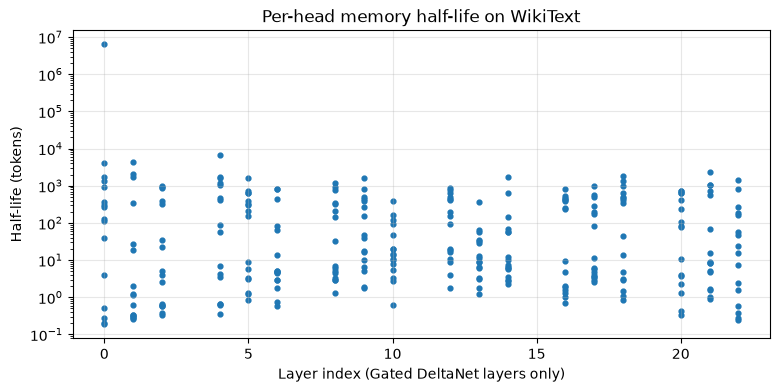

Heads with half-life < 10 tokens: 130 / 288
Heads with half-life > 1,000 tokens: 23 / 288


In [25]:
mixer_inputs: dict[int, torch.Tensor] = {}
handles = [
    layer.linear_attn.register_forward_pre_hook(
        lambda module, args, kwargs, idx=idx: mixer_inputs.__setitem__(
            idx, kwargs["hidden_states"].detach()
        ),
        with_kwargs=True,
    )
    for idx, layer in enumerate(model.model.layers)
    if config.layer_types[idx] == "linear_attention"
]
with torch.no_grad():
    model.model(input_ids[:, :1024], use_cache=False)
for handle in handles:
    handle.remove()

half_lives = {}
with torch.no_grad():
    for idx, x in mixer_inputs.items():
        mixer = model.model.layers[idx].linear_attn.mixer
        # (1, seq_len, num_heads) -> mean log-decay per head
        g = -mixer.A_log.exp() * F.softplus(mixer.in_proj_a(x) + mixer.dt_bias)
        half_lives[idx] = (math.log(0.5) / g.mean(dim=(0, 1))).cpu()

plt.figure(figsize=(9, 4))
for idx, values in half_lives.items():
    plt.scatter([idx] * len(values), values, s=12, color="tab:blue")
plt.yscale("log")
plt.xlabel("Layer index (Gated DeltaNet layers only)")
plt.ylabel("Half-life (tokens)")
plt.title("Per-head memory half-life on WikiText")
plt.grid(alpha=0.3)
plt.show()

all_half_lives = torch.cat(list(half_lives.values()))
num_heads_total = len(all_half_lives)
num_short = (all_half_lives < 10).sum().item()
num_long = (all_half_lives > 1000).sum().item()
print(f"Heads with half-life < 10 tokens: {num_short} / {num_heads_total}")
print(f"Heads with half-life > 1,000 tokens: {num_long} / {num_heads_total}")

The heads split into two populations. Roughly half forget within about 10 tokens and act
as local feature detectors alongside the convolution, while a few dozen keep a write for
thousands of tokens and carry document-level context between the attention layers. Every
layer has both kinds, so the 3 : 1 layout does not rely on attention alone for long range.

In [26]:
attn_inputs: dict[int, torch.Tensor] = {}
handles = [
    layer.self_attn.register_forward_pre_hook(
        lambda module, args, kwargs, idx=idx: attn_inputs.__setitem__(
            idx, kwargs["hidden_states"].detach()
        ),
        with_kwargs=True,
    )
    for idx, layer in enumerate(model.model.layers)
    if config.layer_types[idx] == "full_attention"
]
with torch.no_grad():
    model.model(input_ids[:, :1024], use_cache=False)
for handle in handles:
    handle.remove()

with torch.no_grad():
    for idx, x in attn_inputs.items():
        mixer = model.model.layers[idx].self_attn.mixer
        # (1, seq_len, num_heads, head_dim): second half of each head's q_proj output
        gate = mixer.q_proj(x).view(*x.shape[:2], mixer.num_heads, 2 * mixer.head_dim)[
            ..., mixer.head_dim :
        ]
        gate = torch.sigmoid(gate)
        closed = (gate < 0.1).float().mean()
        print(
            f"Layer {idx:>2}: mean gate {gate.mean():.3f}, fraction < 0.1: {closed:.2%}"
        )

Layer  3: mean gate 0.093, fraction < 0.1: 69.53%
Layer  7: mean gate 0.217, fraction < 0.1: 22.06%
Layer 11: mean gate 0.258, fraction < 0.1: 15.15%
Layer 15: mean gate 0.230, fraction < 0.1: 27.14%
Layer 19: mean gate 0.206, fraction < 0.1: 29.93%
Layer 23: mean gate 0.253, fraction < 0.1: 38.50%


## 3.3 Ablations

Each run disables one component in every layer at inference and recomputes perplexity. The
network was trained with all of them, so the size of the jump shows how much it relies on
each one. This is not what retraining without them would give.

In [27]:
def set_flag(kind: str, attribute: str, value: bool) -> None:
    """Set an attribute on every adapter or mixer of one layer type."""
    for idx, layer in enumerate(model.model.layers):
        if config.layer_types[idx] != kind:
            continue
        adapter = layer.linear_attn if kind == "linear_attention" else layer.self_attn
        setattr(adapter if attribute == "enabled" else adapter.mixer, attribute, value)


ablations = [
    ("No forget gate (alpha = 1)", "linear_attention", "use_forget_gate"),
    ("No attention output gate", "full_attention", "use_output_gate"),
    ("Remove the 6 attention layers", "full_attention", "enabled"),
]
print(f"{'Full model':<32} perplexity {ppl_scratch:>10.2f}")
for name, kind, attribute in ablations:
    set_flag(kind, attribute, False)
    ppl, _ = perplexity(model, input_ids)
    set_flag(kind, attribute, True)
    print(f"{name:<32} perplexity {ppl:>10.2f}")

Full model                       perplexity       9.75


No forget gate (alpha = 1)       perplexity  619996.92


No attention output gate         perplexity 123242298.63


Remove the 6 attention layers    perplexity      58.75


Removing either gate is catastrophic because every later layer then sees activations at a
scale it never saw in training. Removing all six attention layers costs far less on this
slice. Next-token prediction on encyclopedic prose is dominated by local context, which the
Gated DeltaNet layers already model. The attention layers matter most for exact retrieval
over long distances, which a 2,048-token perplexity barely tests.

---
# 4) Cost: Memory and Decode Latency

Qwen3-0.6B-Base is the closest full-attention model in size: 28 layers, all softmax
attention, 8 KV heads of 128 dims. Both models run in bfloat16 here, as they would be
served. Per token, the caches are:

| | Layers holding KV | KV per token | Fixed state |
|---|---|---|---|
| Qwen3-0.6B | 28 | $2 \cdot 28 \cdot 8 \cdot 128 = 57{,}344$ values | none |
| Qwen3.5-0.8B | 6 | $2 \cdot 6 \cdot 2 \cdot 256 = 6{,}144$ values | 18 recurrent states of $16 \times 128 \times 128$ (float32) + conv states |

The measured cache is summed over every tensor the `transformers` cache object holds after
a prefill.

In [28]:
del (
    model,
    originals,
    gdn,
    attention,
    hidden_ref,
    hidden_scratch,
    mixer_inputs,
    attn_inputs,
    captured,
    hf_linear,
    hf_attention,
)
free_memory()


def cache_mib(cache) -> float:
    """Total size of every tensor held by a transformers cache, in MiB."""
    total = 0
    for layer in cache.layers:
        for value in vars(layer).values():
            items = value.values() if isinstance(value, dict) else [value]
            total += sum(
                t.numel() * t.element_size() for t in items if torch.is_tensor(t)
            )
    return total / 2**20


@torch.no_grad()
def measure(
    model: nn.Module, token_ids: torch.Tensor, context_len: int, decode_steps: int = 16
) -> tuple[float, float]:
    """Cache size (MiB) after prefill and mean decode latency (ms/token)."""
    prompt = token_ids[:, :context_len].to(DEVICE)
    out = model(prompt, use_cache=True)
    cache, next_token = out.past_key_values, out.logits[:, -1:].argmax(-1)
    size = cache_mib(cache)
    del out
    sync()
    start = time.time()
    for _ in range(decode_steps):
        step = model(next_token, past_key_values=cache, use_cache=True)
        next_token = step.logits[:, -1:].argmax(-1)
        del step
    sync()
    latency = (time.time() - start) / decode_steps * 1000
    del cache
    free_memory()
    return size, latency

Context lengths stop at 4,096 so that both models fit comfortably on a 16 GB laptop. The
table after the measurements extrapolates from the exact per-token cost.

In [29]:
CONTEXTS = [1024, 2048, 4096]
results = {}
for name in [MODEL_NAME, BASELINE_NAME]:
    # Each model family has its own tokenizer and vocabulary
    token_ids = AutoTokenizer.from_pretrained(name)(text, return_tensors="pt").input_ids
    bf16_model = (
        AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16)
        .to(DEVICE)
        .eval()
    )
    measure(bf16_model, token_ids, 128, decode_steps=2)
    results[name] = [measure(bf16_model, token_ids, n) for n in CONTEXTS]
    del bf16_model
    free_memory()

print("context | Qwen3.5 cache MiB, ms/token | Qwen3 cache MiB, ms/token")
for i, n in enumerate(CONTEXTS):
    size_35, latency_35 = results[MODEL_NAME][i]
    size_3, latency_3 = results[BASELINE_NAME][i]
    qwen35 = f"{size_35:>17.1f}, {latency_35:>8.1f}"
    qwen3 = f"{size_3:>15.1f}, {latency_3:>8.1f}"
    print(f"{n:>7} | {qwen35} | {qwen3}")

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

context | Qwen3.5 cache MiB, ms/token | Qwen3 cache MiB, ms/token
   1024 |              30.8,     24.0 |           112.0,     23.9
   2048 |              42.8,     23.7 |           224.0,     29.1
   4096 |              66.8,     26.8 |           448.0,     41.2


In [30]:
def per_token_and_fixed(sizes: list[tuple[float, float]]) -> tuple[float, float]:
    """Fit cache = fixed + per_token * context from two measurements (MiB)."""
    (first, _), (last, _) = sizes[0], sizes[-1]
    per_token = (last - first) / (CONTEXTS[-1] - CONTEXTS[0])
    return per_token, first - per_token * CONTEXTS[0]


print(f"{'context':>9} | {'Qwen3.5-0.8B':>12} | {'Qwen3-0.6B':>11} | ratio")
fits = {name: per_token_and_fixed(results[name]) for name in results}
for n in [8_192, 32_768, 131_072, 262_144]:
    gib = [(fixed + per_token * n) / 1024 for per_token, fixed in fits.values()]
    print(f"{n:>9,} | {gib[0]:>8.2f} GiB | {gib[1]:>7.2f} GiB | {gib[1] / gib[0]:.1f}x")
per_token_35, fixed_35 = fits[MODEL_NAME]
print()
print(f"Qwen3.5: {per_token_35 * 1024:.1f} KiB/token + {fixed_35:.1f} MiB fixed state")
print(f"Qwen3:   {fits[BASELINE_NAME][0] * 1024:.1f} KiB/token")

  context | Qwen3.5-0.8B |  Qwen3-0.6B | ratio
    8,192 |     0.11 GiB |    0.88 GiB | 7.8x
   32,768 |     0.39 GiB |    3.50 GiB | 8.9x
  131,072 |     1.52 GiB |   14.00 GiB | 9.2x
  262,144 |     3.02 GiB |   28.00 GiB | 9.3x

Qwen3.5: 12.0 KiB/token + 18.8 MiB fixed state
Qwen3:   112.0 KiB/token


The fixed 18.8 MiB is the 18 recurrent states ($18 \times 16 \times 128 \times 128$
float32 values = 18 MiB) plus the convolution buffers. Past a few thousand tokens the gap
settles at about 9.3×, set by the per-token cost; at 262K tokens Qwen3-0.6B would need
28 GiB of cache. Qwen3.5's decode latency stays nearly flat over 1K–4K tokens, while
Qwen3's rises with the cache it has to read at every step.

---
# 5) Long context with YaRN

Qwen3.5 is trained to 262,144 tokens; the model card extends it to about 1M with
**YaRN**, `factor = 4`. RoPE pair $i$ rotates at frequency $\theta_i = b^{-2i/d}$ (base $b$,
rotary dimension $d$) with wavelength $\lambda_i = 2\pi / \theta_i$. Two earlier fixes:

- **Position interpolation** divides every frequency by the factor $s$. Long wavelengths
  then stay inside the trained range, but the short ones that encode local order get
  squeezed.
- **NTK-aware scaling** raises the base instead, which spreads the change unevenly but
  still alters every pair.

**YaRN** splits pairs by how many full rotations $r_i = L_{\text{train}} / \lambda_i$ they
complete within the training length $L_{\text{train}}$:
- pairs with $r_i > \beta_{\text{fast}} = 32$ keep their frequency;
- pairs with $r_i < \beta_{\text{slow}} = 1$ are interpolated by $1/s$;
- pairs in between follow a linear ramp.

It also multiplies the cos/sin tables by $0.1 \ln s + 1$, which sharpens the softmax to
offset its flattening over more keys.

Two Qwen3.5 specifics change the picture:
- with partial RoPE there are only 32 frequency pairs;
- YaRN touches only the **6 attention layers**, since the 18 Gated DeltaNet layers have no
  positions to rescale.

In [31]:
def yarn_inv_freq(
    rotary_dim: int,
    base: float,
    factor: float,
    original_max_len: int,
    beta_fast: float = 32.0,
    beta_slow: float = 1.0,
) -> tuple[torch.Tensor, float]:
    """YaRN inverse frequencies (rotary_dim // 2,) and the cos/sin scale factor."""
    inv_freq = 1.0 / (base ** (torch.arange(0, rotary_dim, 2).float() / rotary_dim))

    # Pair index at which a frequency completes `rotations` turns over original_max_len
    def pair_for(rotations: float) -> float:
        return (
            rotary_dim
            * math.log(original_max_len / (rotations * 2 * math.pi))
            / (2 * math.log(base))
        )

    low = max(math.floor(pair_for(beta_fast)), 0)
    high = min(math.ceil(pair_for(beta_slow)), rotary_dim - 1)
    # 0 = keep frequency, 1 = fully interpolate, linear in between
    ramp = (
        (torch.arange(rotary_dim // 2).float() - low) / max(high - low, 1e-3)
    ).clamp(0, 1)
    scaled = inv_freq * (1 - ramp) + (inv_freq / factor) * ramp
    return scaled, 0.1 * math.log(factor) + 1.0

Max |inv_freq - transformers|: 0.00e+00
Attention factor: 1.1386 (reference 1.1386)
Pairs kept: 15, ramped: 7, interpolated: 10


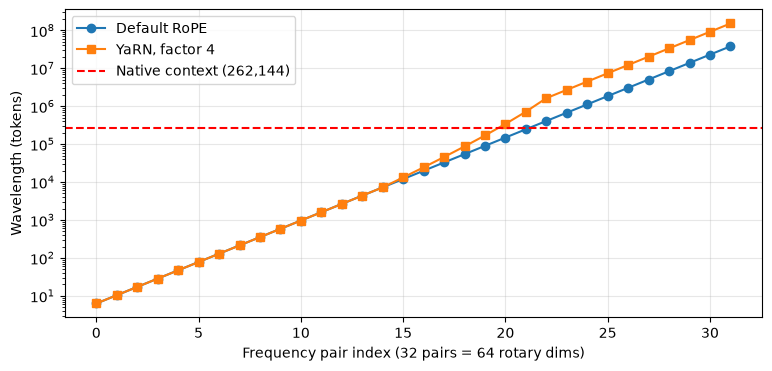

In [32]:
YARN = {"factor": 4.0, "original_max_position_embeddings": 262_144}
inv_freq_yarn, attention_factor = yarn_inv_freq(
    ROTARY_DIM, ROPE_THETA, YARN["factor"], YARN["original_max_position_embeddings"]
)

yarn_config = copy.deepcopy(config)
yarn_config.rope_parameters = {**config.rope_parameters, "rope_type": "yarn", **YARN}
inv_freq_ref, attention_factor_ref = ROPE_INIT_FUNCTIONS["yarn"](yarn_config)
print(
    f"Max |inv_freq - transformers|: {(inv_freq_yarn - inv_freq_ref).abs().max():.2e}"
)
print(
    f"Attention factor: {attention_factor:.4f} (reference {attention_factor_ref:.4f})"
)

inv_freq = 1.0 / (ROPE_THETA ** (torch.arange(0, ROTARY_DIM, 2).float() / ROTARY_DIM))
ratio = inv_freq / inv_freq_yarn
kept, interpolated = (ratio < 1.001).sum().item(), (ratio > 3.999).sum().item()
ramped = len(ratio) - kept - interpolated
print(f"Pairs kept: {kept}, ramped: {ramped}, interpolated: {interpolated}")

plt.figure(figsize=(9, 4))
plt.semilogy(2 * math.pi / inv_freq, "o-", label="Default RoPE")
plt.semilogy(2 * math.pi / inv_freq_yarn, "s-", label="YaRN, factor 4")
plt.axhline(
    YARN["original_max_position_embeddings"],
    color="red",
    linestyle="--",
    label="Native context (262,144)",
)
plt.xlabel("Frequency pair index (32 pairs = 64 rotary dims)")
plt.ylabel("Wavelength (tokens)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The 15 highest-frequency pairs complete more than 32 rotations within 262K tokens and keep
their frequency, so local word order is untouched. The 10 lowest-frequency pairs, whose
wavelengths already exceed the native context, are stretched 4×, and the 7 pairs in
between follow the ramp.

---
# 6) Variants

| Model | Linear mixer | Ratio linear : full | What differs from Qwen3.5 |
|---|---|---|---|
| Qwen3-Next-80B-A3B (Sep 2025) | Gated DeltaNet | 3 : 1 | Same design at 80B with 512-expert MoE; the prototype for Qwen3.5 |
| Qwen3.8-Flash-Next (Aug 2026) | Gated DeltaNet | 3 : 1 | Its config adds an indexer (`indexer_budget`, `indexer_compress_ratio`) that selects compressed key blocks for the full-attention layers, plus 512-expert MoE |
| Kimi Linear | Kimi Delta Attention | 3 : 1 (with MLA) | Forget gate per channel instead of a single scalar $\alpha_t$ per head |
| MiniMax-01 / M1 | Lightning attention (plain linear attention) | 7 : 1 | No delta rule; MiniMax-M2 later went back to full attention |
| Mamba-2 hybrids (Jamba, Nemotron-H) | Selective SSM | about 7 : 1 to 12 : 1 | Decayed additive write $S_t = \alpha_t S_{t-1} + k_t v_t^\top$: the forget gate without the delta correction |
| DeltaNet | Delta rule | — | No forget gate ($\alpha_t = 1$) |